# Tome S2, Chapter 11: Convex bodies (Python companion)

Exercises first, solutions at the end. We throw a million needles and a few noodles, put Lazzarini's luck on trial, find Radon points, check Cauchy's formula on random polygons and on the Reuleaux triangle, and test the Brunn–Minkowski inequality on convex and very non-convex sets. We use `numpy`, `scipy` and `matplotlib`.

*Before each solution, predict what the output will look like.*

In [1]:
import math
import numpy as np
from scipy.signal import fftconvolve
from scipy.stats import binom
import matplotlib.pyplot as plt
rng = np.random.default_rng(11)

## Exercises

**P11.1 (★) Needles and noodles.** Simulate Buffon's experiment with $\ell=0.8$ for $n=10^2,\dots,10^6$ throws and plot the error of the estimate of $\pi$ against $n$. Then throw random polygonal noodles and check $\mathbb E[N]=\frac{2L}\pi$ (Theorem 11.4).

**P11.2 (★) Lazzarini on trial.** With $\ell=\frac56$, what is the probability that $3408$ honest throws give exactly $1808$ crossings (Exercise 11.5)? Simulate experimenters who stop at the first time $n\le 5000$ at which their estimate is within $10^{-6}$ of $\pi$: how many succeed?

**P11.3 (★) Radon and Helly.** Find a Radon partition (Lemma 11.1) of random point sets in $\mathbb R^2$ and $\mathbb R^3$. Then, for random families of disks in the plane, check Theorem 11.2: whenever every three meet, all meet.

**P11.4 (★★) Cauchy's formula.** For random convex polygons, compare the perimeter with $\int_0^\pi w(\theta)\,d\theta$ (Theorem 11.5). Check that the Reuleaux triangle of width $1$ has constant width and perimeter $\pi$ (Corollary 11.6).

**P11.5 (★★) Brunn–Minkowski.** Test Theorem 11.7 on random convex polygons, and on random non-convex pixel sets (computing $A+B$ by a convolution). How close to equality can you get?

## Solutions

### P11.1
**How to find it.** Only the vertical offset and the angle matter. A noodle is a random walk with steps of random lengths; its crossings are the crossings of its segments.

n =      100   pi estimate = 2.90909
n =     1000   pi estimate = 3.12500
n =    10000   pi estimate = 3.08821
n =   100000   pi estimate = 3.14040


n =  1000000   pi estimate = 3.14233


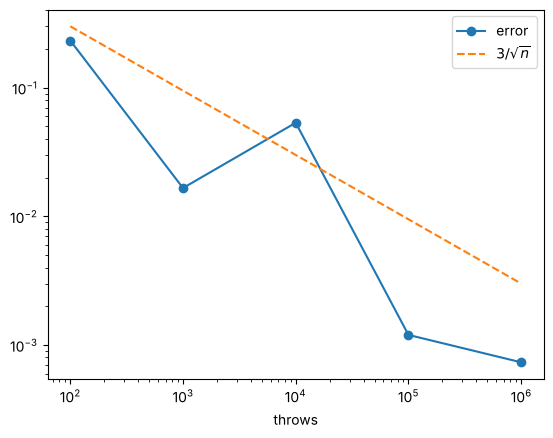

noodle length 6.622   E[N] = 4.207   2L/pi = 4.216


noodle length 7.258   E[N] = 4.629   2L/pi = 4.621


noodle length 5.819   E[N] = 3.706   2L/pi = 3.705


In [2]:
def throw(n, ell=0.8):
    y = rng.uniform(0, 1, n); th = rng.uniform(0, math.pi, n)
    h = 0.5 * ell * np.sin(th)
    return np.floor(y - h) != np.floor(y + h)
ns = [10**k for k in range(2, 7)]
errs = []
for n in ns:
    p = throw(n).mean(); est = 2 * 0.8 / p; errs.append(abs(est - math.pi))
    print('n = %8d   pi estimate = %.5f' % (n, est))
plt.loglog(ns, errs, 'o-', label='error'); plt.loglog(ns, [3 / math.sqrt(n) for n in ns], '--', label='$3/\\sqrt{n}$'); plt.legend(); plt.xlabel('throws'); plt.show()

def noodle_crossings(pts, trials=20000):
    L = np.sum(np.linalg.norm(np.diff(pts, axis=0), axis=1))
    tot = 0
    for _ in range(trials):
        th = rng.uniform(0, 2 * math.pi); u = rng.uniform()
        y = pts[:, 0] * math.sin(th) + pts[:, 1] * math.cos(th) + u
        k = np.floor(y)
        tot += np.sum(np.abs(np.diff(k)))           # number of integers between consecutive vertices
    return L, tot / trials
for _ in range(3):
    steps = rng.normal(size=(12, 2)) * 0.4
    pts = np.vstack([[0, 0], np.cumsum(steps, axis=0)])
    L, EN = noodle_crossings(pts)
    print('noodle length %.3f   E[N] = %.3f   2L/pi = %.3f' % (L, EN, 2 * L / math.pi))

The error decreases like $1/\sqrt n$: about one more digit per hundredfold increase in throws. Noodles obey the same law as needles.

### P11.2
**How to find it.** The number of crossings is binomial with $p=\frac{5}{3\pi}$. For the stopping experiment, track the running estimate.

In [3]:
p = 5 / (3 * math.pi)
print('P(exactly 1808 of 3408) = %.4f' % binom.pmf(1808, 3408, p))
succ = 0; trials = 2000
for _ in range(trials):
    hits = np.cumsum(rng.uniform(size=5000) < p); n = np.arange(1, 5001)
    est = np.where(hits > 0, 2 * (5 / 6) * n / np.maximum(hits, 1), np.inf)
    succ += np.any(np.abs(est - math.pi) < 1e-6)
print('experimenters who can stop with 6 correct decimals: %d of %d' % (succ, trials))

P(exactly 1808 of 3408) = 0.0137
experimenters who can stop with 6 correct decimals: 675 of 2000


An honest run of $3408$ throws lands on exactly $1808$ crossings with probability about $1.4\%$. But an experimenter who may stop whenever they like does much better: about a third of our simulated experimenters hit six correct decimals before $5000$ throws, always at a number of throws that is a multiple of $213$, where the estimate can equal $\frac{355}{113}$. Six decimals from a few thousand throws are a sign of optional stopping (or of a convenient choice of the number of throws), not of a good needle: an honest fixed-size experiment would need about $10^{13}$ throws.

### P11.3
**How to find it.** A Radon partition comes from a null vector of the matrix with columns $(x_i,1)$. For disks, we look for common points among the points of a fine grid.

In [4]:
def radon(X):
    A = np.vstack([X.T, np.ones(len(X))])
    lam = np.linalg.svd(A)[2][-1]
    I = lam > 0; s = lam[I].sum()
    p = (lam[I] @ X[I]) / s; q = (-lam[~I] @ X[~I]) / s
    return I, p, q
for d in (2, 3):
    X = rng.normal(size=(d + 2, d)); I, p, q = radon(X)
    print('dimension', d, ' split', I.astype(int), ' common point', np.round(p, 4), ' check', np.allclose(p, q))

G = np.stack(np.meshgrid(np.linspace(-3, 3, 400), np.linspace(-3, 3, 400)), -1).reshape(-1, 2)
def inside(c, r): return np.linalg.norm(G - c, axis=1) <= r
checked = 0
for _ in range(300):
    m = 6; cs = rng.normal(size=(m, 2)) * 0.8; rs = rng.uniform(0.6, 1.4, m)
    masks = [inside(c, r) for c, r in zip(cs, rs)]
    triples = all(np.any(masks[i] & masks[j] & masks[k]) for i in range(m) for j in range(i) for k in range(j))
    if triples:
        checked += 1
        assert np.any(np.logical_and.reduce(masks))
print(checked, 'families with all triples meeting: all of them have a common point')

dimension 2  split [0 0 0 1]  common point [-1.5497  0.613 ]  check True
dimension 3  split [0 1 0 0 1]  common point [ 0.0035  0.1787 -0.3932]  check True


60 families with all triples meeting: all of them have a common point


(The grid test can only find common points up to the grid resolution, but with these sizes it never failed.)

### P11.4
**How to find it.** The width in direction $\theta$ is $\max_i v_i\cdot u-\min_i v_i\cdot u$ over the vertices, with $u=(\cos\theta,\sin\theta)$. For the Reuleaux triangle, sample its three arcs.

In [5]:
def convex_hull(P):
    P = sorted(map(tuple, P))
    def half(P):
        h = []
        for p in P:
            while len(h) >= 2 and (h[-1][0]-h[-2][0])*(p[1]-h[-2][1]) - (h[-1][1]-h[-2][1])*(p[0]-h[-2][0]) <= 0: h.pop()
            h.append(p)
        return h
    return np.array(half(P)[:-1] + half(P[::-1])[:-1])
def perimeter(V): return np.sum(np.linalg.norm(V - np.roll(V, 1, axis=0), axis=1))
th = np.linspace(0, math.pi, 20001)
U = np.stack([np.cos(th), np.sin(th)], 1)
def width(V): proj = V @ U.T; return proj.max(0) - proj.min(0)
for _ in range(4):
    V = convex_hull(rng.normal(size=(15, 2)))
    print('perimeter %.6f   integral of width %.6f' % (perimeter(V), np.trapezoid(width(V), th)))
T = [np.array([0, 0.]), np.array([1, 0.]), np.array([.5, math.sqrt(3) / 2])]
arc = []
for i in range(3):
    c, a, b = T[i], T[(i + 1) % 3], T[(i + 2) % 3]
    t0, t1 = math.atan2(*(a - c)[::-1]), math.atan2(*(b - c)[::-1])
    if t1 < t0: t1 += 2 * math.pi
    arc += [c + np.array([math.cos(t), math.sin(t)]) for t in np.linspace(t0, t1, 3000)]
Rl = np.array(arc); w = width(Rl)
print('Reuleaux: width between %.6f and %.6f, perimeter %.6f, pi = %.6f' % (w.min(), w.max(), perimeter(Rl), math.pi))

perimeter 11.346956   integral of width 11.346956
perimeter 10.152260   integral of width 10.152260
perimeter 12.575155   integral of width 12.575155
perimeter 11.451570   integral of width 11.451570


Reuleaux: width between 1.000000 and 1.000000, perimeter 3.141593, pi = 3.141593


### P11.5
**How to find it.** For convex polygons, $A+B$ is the convex hull of the sums of vertices. For pixel sets, $A+B$ is the support of the convolution of the indicator arrays (each pixel a small square, so this is the Minkowski sum of unions of boxes).

In [6]:
def area(V): x, y = V[:, 0], V[:, 1]; return 0.5 * abs(np.dot(x, np.roll(y, -1)) - np.dot(y, np.roll(x, -1)))
ratios = []
for _ in range(2000):
    A = convex_hull(rng.normal(size=(rng.integers(3, 9), 2)) * rng.uniform(.3, 2, 2))
    B = convex_hull(rng.normal(size=(rng.integers(3, 9), 2)) * rng.uniform(.3, 2, 2))
    S = convex_hull((A[:, None, :] + B[None, :, :]).reshape(-1, 2))
    ratios.append(math.sqrt(area(S)) / (math.sqrt(area(A)) + math.sqrt(area(B))))
print('convex polygons: min ratio sqrt|A+B| / (sqrt|A| + sqrt|B|) = %.4f' % min(ratios))
for _ in range(4):
    a = rng.uniform(size=(40, 40)) < 0.15; b = rng.uniform(size=(40, 40)) < 0.15
    s = fftconvolve(a.astype(float), b.astype(float)) > 0.5      # lower-left corners i+j of the sums of pixels
    # pixel (i, j) is the unit square [i, i+1) x [j, j+1); the sum of two unit squares is a 2x2 square at the sum of corners
    sq = fftconvolve(s.astype(float), np.ones((2, 2))) > 0.5     # union of those 2x2 squares, as unit pixels
    print('random pixel sets: |A| = %d, |B| = %d, |A+B| = %d,  sqrt|A+B| - sqrt|A| - sqrt|B| = %.2f'
          % (a.sum(), b.sum(), sq.sum(), math.sqrt(sq.sum()) - math.sqrt(a.sum()) - math.sqrt(b.sum())))

convex polygons: min ratio sqrt|A+B| / (sqrt|A| + sqrt|B|) = 1.0302
random pixel sets: |A| = 236, |B| = 258, |A+B| = 6119,  sqrt|A+B| - sqrt|A| - sqrt|B| = 46.80
random pixel sets: |A| = 241, |B| = 243, |A+B| = 6152,  sqrt|A+B| - sqrt|A| - sqrt|B| = 47.32
random pixel sets: |A| = 242, |B| = 266, |A+B| = 6128,  sqrt|A+B| - sqrt|A| - sqrt|B| = 46.42
random pixel sets: |A| = 237, |B| = 232, |A+B| = 6117,  sqrt|A+B| - sqrt|A| - sqrt|B| = 47.58


For convex polygons the ratio stays above $1$ and approaches it for nearly homothetic shapes (equality holds exactly for homothetic convex sets). Sparse random pixel sets have a sum that is far larger than the inequality requires: adding a scattered set to itself fills in the gaps.